<a href="https://colab.research.google.com/github/B-HJ/Yolov11/blob/main/Inchang_Yolov11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import os
from ultralytics import YOLO

# YOLOv11 사전 학습된 모델 로드
model = YOLO('yolo11n.pt')

# 실제 파일이 위치한 경로와 정확한 확장자로 변경합니다.
video_files = [
    'sample_data/1.mov',
    'sample_data/2.mp4',
    'sample_data/3.mp4'
]

for video in video_files:
    if os.path.exists(video):
        print(f"--- {video} 객체 탐지 시작 ---")
        # 추론 결과는 'runs/detect/predict' 폴더 안에 저장됩니다.
        results = model.predict(source=video, save=True, conf=0.25)
        print(f"--- {video} 완료 (결과 저장됨) ---\n")
    else:
        print(f"파일을 찾을 수 없습니다: {video}. 파일 경로와 확장자를 다시 확인해 주세요.")

--- sample_data/1.mov 객체 탐지 시작 ---

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/243) /content/sample_data/1.mov: 384x640 1 cup, 1 chair, 1 laptop, 77.1ms
video 1/1 (frame 2/243) /content/sample_data/1.mov: 384x640 1 cup, 1 chair, 1 laptop, 1 cell phone, 72.2ms
video 1/1 (frame 3/243) /content/sample_data/1.mov: 384x640 1 chair, 1 laptop, 69.5ms
video 1/1 (frame 4/243) /content/sample_data/1.mov: 384x640 1 chair, 1 laptop, 74.0ms
video 1/1 (frame 5/243) /content/sample_data/1.mov: 

### 3. 영상 내 사람 수 감지 및 실시간 텍스트 표시 비디오 생성
`sample_data/2.mp4` 파일에서 사람(Person) 클래스만 카운트하여 화면에 표시하고 새로운 영상으로 저장하는 코드입니다.

In [9]:
import cv2
from ultralytics import YOLO

# YOLOv11 모델 로드
model = YOLO('yolo11n.pt')

# 입력 영상 및 출력 영상 경로 설정
input_video_path = 'sample_data/2.mp4'
output_video_path = 'sample_data/2_people_count.mp4'

# 비디오 캡처 객체 생성
cap = cv2.VideoCapture(input_video_path)

# 비디오 속성 정보 획득
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# 출력을 위한 VideoWriter 정의 (MP4 형식을 지원하는 mp4v 코덱 사용)
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_video_path, fourcc, fps, (width, height))

print("영상 분석 및 인원수 작성 시작...")
frame_count = 0

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # YOLOv11을 통해 현재 프레임 감지 진행
    results = model(frame, verbose=False)

    # 감지 결과에서 'person' (COCO class 0)의 수 세기
    person_count = 0
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        if class_id == 0:  # 0번 클래스가 'person' (사람)입니다
            person_count += 1

            # 사람의 위치에 바운딩 박스 그리기
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(frame, "Person", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    # 화면 왼쪽 상단에 실시간으로 사람 수 텍스트 작성
    text = f"People Count: {person_count}"
    # 가독성을 위해 배경 검은색 상자 그리기
    cv2.rectangle(frame, (20, 20), (320, 80), (0, 0, 0), -1)
    # 흰색 글씨로 사람 수 쓰기
    cv2.putText(frame, text, (30, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)

    # 프레임 저장
    out.write(frame)

    frame_count += 1
    if frame_count % 50 == 0:
         print(f"진행률: {frame_count}/{total_frames} 프레임 처리 완료...")

# 작업 완료 후 리소스 해제
cap.release()
out.release()
print(f"\n분석 완료! 결과 영상이 '{output_video_path}' 에 성공적으로 저장되었습니다.")

영상 분석 및 인원수 작성 시작...
진행률: 50/200 프레임 처리 완료...
진행률: 100/200 프레임 처리 완료...
진행률: 150/200 프레임 처리 완료...
진행률: 200/200 프레임 처리 완료...

분석 완료! 결과 영상이 'sample_data/2_people_count.mp4' 에 성공적으로 저장되었습니다.


### 4. YOLOv11x 모델을 사용한 1.mov 객체 탐지
가장 강력한 크기의 모델인 `yolo11x.pt`를 사용하여 `/content/sample_data/1.mov` 영상을 분석합니다.

In [10]:
from ultralytics import YOLO
import os

# YOLOv11x 모델 로드 (가장 정교한 검출 성능)
model_x = YOLO('yolo11x.pt')

video_path = 'sample_data/1.mov'

if os.path.exists(video_path):
    print(f"--- {video_path} 객체 탐지 시작 (Model: YOLOv11x) ---")
    # 결과를 runs/detect/predict 디렉토리에 저장합니다.
    results = model_x.predict(source=video_path, save=True, conf=0.25)
    print(f"\n--- {video_path} 완료! 결과가 성공적으로 저장되었습니다. ---")
else:
    print(f"파일을 찾을 수 없습니다: {video_path}")

--- sample_data/1.mov 객체 탐지 시작 (Model: YOLOv11x) ---

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/243) /content/sample_data/1.mov: 384x640 3 chairs, 1510.3ms
video 1/1 (frame 2/243) /content/sample_data/1.mov: 384x640 2 chairs, 1 tv, 1504.4ms
video 1/1 (frame 3/243) /content/sample_data/1.mov: 384x640 2 chairs, 1 tv, 1497.2ms
video 1/1 (frame 4/243) /content/sample_data/1.mov: 384x640 4 chairs, 2 tvs, 1588.0ms
video 1/1 (frame 5/243) /content/sample_data/1.mov: 384x640 3 chairs, 1

### 5. YOLOv11 Pose 모델을 이용한 포즈 추정 및 이미지 표시
`dancing.png` 이미지를 분석하고 키포인트가 표시된 결과 이미지를 Colab 화면에 곧바로 보여줍니다.


image 1/1 /content/dancing.png: 384x640 7 persons, 1555.2ms
Speed: 1.9ms preprocess, 1555.2ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)


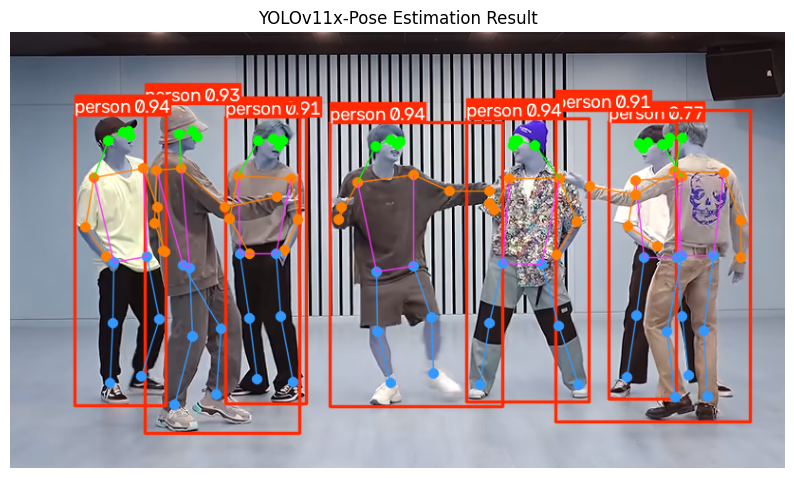

In [11]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# YOLOv11x Pose 모델 로드
model_pose = YOLO('yolo11x-pose.pt')

# 이미지 경로 지정
image_path = 'dancing.png'

if os.path.exists(image_path):
    # 포즈 예측 수행
    results = model_pose(image_path)

    # 결과 이미지 가져오기 (YOLO 자체 드로잉 결과)
    # results[0].plot()은 RGB 형태의 NumPy 배열을 반환합니다.
    annotated_image = results[0].plot()

    # Colab에서 이미지를 보여주기 위해 matplotlib 사용
    plt.figure(figsize=(10, 10))
    plt.imshow(annotated_image)
    plt.axis('off')
    plt.title("YOLOv11x-Pose Estimation Result")
    plt.show()
else:
    print(f"'{image_path}' 파일을 찾을 수 없습니다. 바탕화면의 파일을 Colab 파일 탭에 드래그하여 업로드해 주세요.")

Yolov11

### 1. Ultralytics 패키지 설치
YOLOv11을 실행하기 위해 `ultralytics` 라이브러리를 설치합니다.

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


### 2. YOLOv11 모델을 로드하여 영상 객체 탐지 실행
업로드하신 영상 파일명과 확장자에 맞게 아래 코드의 `video_files` 목록을 수정해 주세요 (예: `'1.mp4'`, `'2.mp4'`, `'3.mp4'`).

In [6]:
import os
from ultralytics import YOLO

# YOLOv11 사전 학습된 모델 로드 (yolo11n.pt, yolo11s.pt 등 선택 가능)
model = YOLO('yolo11n.pt')

# 업로드한 파일명과 확장자를 정확하게 입력해 주세요.
# 예: '1.mp4', '2.avi' 등
video_files = ['1.mov', '2.mov', '3.mov']

for video in video_files:
    if os.path.exists(video):
        print(f"--- {video} 객체 탐지 시작 ---")
        # 추론 결과는 'runs/detect/predict' 폴더 안에 저장됩니다.
        results = model.predict(source=video, save=True, conf=0.25)
        print(f"--- {video} 완료 (결과 저장됨) ---\n")
    else:
        print(f"파일을 찾을 수 없습니다: {video}. Colab 파일 탭에 업로드되었는지 확인해 주세요.")

파일을 찾을 수 없습니다: 1.mov. Colab 파일 탭에 업로드되었는지 확인해 주세요.
파일을 찾을 수 없습니다: 2.mov. Colab 파일 탭에 업로드되었는지 확인해 주세요.
파일을 찾을 수 없습니다: 3.mov. Colab 파일 탭에 업로드되었는지 확인해 주세요.
